# Fit ERP (dipole) + MUA with HNN
Objective: weighted mean of (1 - correlation) for the dipole and each MUA trace.

Simulated signals (chosen per target in `mua_targets`):
- MUA (target has `depth`): from the simulated extracellular field (band-pass 300-5000 Hz -> rectify -> low-pass 200 Hz) at that depth. Needs a small `dt` (0.025 ms or less).
- FR (target has `cell_types`): firing rate, i.e. smoothed spike count of those cell types.

In [1]:
from hnn_core.optimization import Optimizer, add_opt_drives, set_params_opt_drives
from hnn_core.optimization.objective_functions import _check_is_batch
from hnn_core.batch_simulate import BatchSimulate
from hnn_core import jones_2009_model, simulate_dipole
from hnn_core.network_models import add_erp_drives_to_jones_model
from hnn_core.extracellular import calculate_csd2d, _get_laminar_z_coords
from hnn_core.dipole import _corr

import pickle
from hnn_core import JoblibBackend

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import CubicSpline
from scipy import signal

## Experimental data

In [2]:
# CAUTION: The following code is for setting up the machinery only. It uploads csd data instead of MUA.
df_erp = pd.read_csv('../data/2-pb3738017_trace8_with_time.txt', delimiter=' ') # dipole
cs_erp = CubicSpline(df_erp['time_ms'], df_erp['csd_trace8'])

df_mua_supra = pd.read_csv('../data/2-pb3738017_trace8_with_time.txt', delimiter=' ')
cs_mua_supra = CubicSpline(df_mua_supra['time_ms'], df_mua_supra['csd_trace8'])

df_mua_infra = pd.read_csv('../data/2-pb3738017_trace16_with_time.txt', delimiter=' ')
cs_mua_infra = CubicSpline(df_mua_infra['time_ms'], df_mua_infra['csd_trace16'])


#df_csd1 = pd.read_csv('../data/2-pb3738017_trace8_with_time.txt', delimiter=' ')
#cs_csd1 = CubicSpline(df_csd1['time_ms'], df_csd1['csd_trace8'])

#df_csd2 = pd.read_csv('../data/2-pb3738017_trace16_with_time.txt', delimiter=' ')
#cs_csd2 = CubicSpline(df_csd2['time_ms'], df_csd2['csd_trace16'])

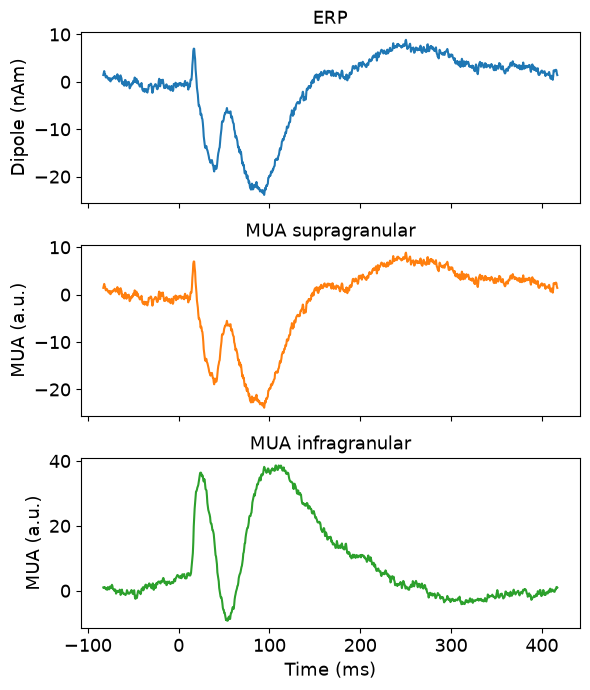

In [3]:
labelsize = 13
ticksize = 13
legendsize = 13

# Update the column names when the real MUA/ERP files arrive!!
traces = [
    ('ERP', df_erp, 'csd_trace8',  'Dipole (nAm)', 'C0'),
    ('MUA supragranular', df_mua_supra, 'csd_trace8',  'MUA (a.u.)',   'C1'),
    ('MUA infragranular', df_mua_infra, 'csd_trace16', 'MUA (a.u.)',   'C2'),
]

fig, axes = plt.subplots(len(traces), 1, figsize=(6, 7), sharex=True)

for ax, (title, df, col, ylabel, color) in zip(axes, traces):
    ax.plot(df['time_ms'], df[col], color=color, linewidth=1.5)
    ax.set_title(title, fontsize=labelsize)
    ax.set_ylabel(ylabel, fontsize=labelsize)
    ax.tick_params(labelsize=ticksize)

axes[-1].set_xlabel('Time (ms)', fontsize=labelsize)
fig.tight_layout()

## Settings and baseline simulation

In [4]:
n_trials = 1
scaling_factor = 1000
window_length = 40
tstop = 200      # make sure it covers the time range of the ERP/MUA data!
# MUA (from the extracellular field) needs a fine time step: the 300-5000 Hz band must stay below fs/2.
# dt = 0.025 ms -> fs = 40 kHz (HNN default). dt = 0.5 ms (fs = 2 kHz) is too coarse.
# Smaller dt (e.g. 0.00625) is more accurate but 4 times slower.
dt = 0.025

# Optimizer size: small values for testing; e.g. max_iter=100, popsize=100 for a real run on cluster
max_iter = 2
popsize = 4
n_jobs = 4       # parallel simulations: ~number of CPU cores on laptop, more on the cluster

w_dpl = 0.5            # weight of the dipole in the total loss (MUA traces share the rest)
fr_smooth_ms = 5.0     # smoothing of simulated firing rate (FR), in ms; only used for 'cell_types' targets

net = jones_2009_model()
add_erp_drives_to_jones_model(net)

# Laminar electrode array (kept for extracting MUA from the extracellular field)
#depths = np.arange(-325, 2150, 100)
depths = np.arange(-550, 2150, 100) # check this with my CSD decomposition codes!
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('shank1', electrode_pos)

dpl = simulate_dipole(net, tstop=tstop, dt=dt, verbose=False)

In [5]:
times = dpl[0].times

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['shank1'].positions)

exp_erp       = cs_erp(times)
exp_mua_supra = cs_mua_supra(times)
exp_mua_infra = cs_mua_infra(times)

#hnn_csd_data = calculate_csd2d(lfp_data=net.rec_arrays['shank1'].voltages[0], delta=delta)
#exp_csd1 = cs_csd1(times)
#exp_csd2 = cs_csd2(times)

## Simulated MUA and FR

In [6]:
def _process_fr(net, times, cell_types, smooth_ms=5.0, trial_idx=0):
    """Simulated firing rate (FR) = smoothed population spike count of the given cell types,
    on the same time grid as `times`."""
    dt = times[1] - times[0]
    spike_times = np.array(net.cell_response.spike_times[trial_idx])
    spike_types = np.array(net.cell_response.spike_types[trial_idx])

    # keep only spikes from the chosen cell types (this also excludes the drive inputs)
    mask = np.isin(spike_types, cell_types)

    # count spikes in bins centred on the time grid
    bins = np.append(times, times[-1] + dt) - dt / 2
    counts, _ = np.histogram(spike_times[mask], bins=bins)

    # Gaussian smoothing
    sigma = smooth_ms / dt
    k = np.arange(-int(4 * sigma), int(4 * sigma) + 1)
    kernel = np.exp(-0.5 * (k / sigma) ** 2)
    kernel /= kernel.sum()
    return np.convolve(counts, kernel, mode='same')


def _safe_corr(a, b):
    """Correlation that returns 0 instead of NaN when a trace is flat
    (e.g. a network where the chosen cells never spike)."""
    if np.std(a) == 0 or np.std(b) == 0:
        return 0.0
    return np.corrcoef(a, b)[0, 1]


def _mua_all_contacts(net, band=(300, 5000), env_cutoff=200, array_name='shank1'):
    """MUA at every contact, from the simulated extracellular field:
    band-pass -> rectify -> low-pass, averaged over trials.
    Returns (rec_times, mua) with mua of shape (n_contacts, n_times)."""
    arr = net.rec_arrays[array_name]
    rec_times = np.array(arr.times)
    fs = 1000 / (rec_times[1] - rec_times[0])          # Hz (times are in ms)
    if band[1] >= fs / 2:
        raise ValueError(f"MUA band {band} Hz is too high for fs = {fs:.0f} Hz: use a smaller dt")

    # output='ba' (the default) gives one pair of polynomial coefficient lists for the whole filter.
    # output='sos' gives the same filter split into a chain of small second-order filters, applied one after another.
    sos_bp = signal.butter(4, band, btype='bandpass', output='sos', fs=fs)
    sos_env = signal.butter(4, env_cutoff, btype='lowpass', output='sos', fs=fs)

    voltages = np.array(arr.voltages)  # (n_trials, n_contacts, n_times)
    rectified = np.abs(signal.sosfiltfilt(sos_bp, voltages, axis=-1))  # Band-pass filter and rectify
    mua = signal.sosfiltfilt(sos_env, rectified, axis=-1).mean(axis=0)  # low pass filter and envelope
    return rec_times, mua


def _process_mua(net, times, depth, array_name='shank1', **kwargs):
    """MUA at the contact closest to `depth`, on the time grid `times`."""
    rec_times, mua = _mua_all_contacts(net, array_name=array_name, **kwargs)
    contact_depths = np.array(net.rec_arrays[array_name].positions)[:, 2]
    c = np.argmin(np.abs(contact_depths - depth))
    return np.interp(times, rec_times, mua[c])


def _sim_mua(net, times, m, fr_smooth_ms=5.0):
    """Simulated signal to compare with one entry of mua_targets, averaged over trials.
    Entry with 'depth'      -> MUA from the extracellular field at that depth.
    Entry with 'cell_types' -> firing rate (FR) of those cell types."""
    if 'depth' in m:
        return _process_mua(net, times, m['depth'])
    n_tr = len(net.cell_response.spike_times)
    return np.mean([_process_fr(net, times, m['cell_types'], smooth_ms=fr_smooth_ms, trial_idx=t)
                    for t in range(n_tr)], axis=0)


# One entry per MUA channel. Add eventually channels 3 and 4.
# Use 'depth' (um, HNN coordinates) to compare with simulated MUA (extracellular field),
# or 'cell_types' instead (e.g. ('L2_pyramidal',)) to compare with the firing rate (FR).
mua_targets = [
    {'name': 'MUA supragranular', 'trace': exp_mua_supra, 'depth': 1250},
    {'name': 'MUA infragranular', 'trace': exp_mua_infra, 'depth': 250},
]

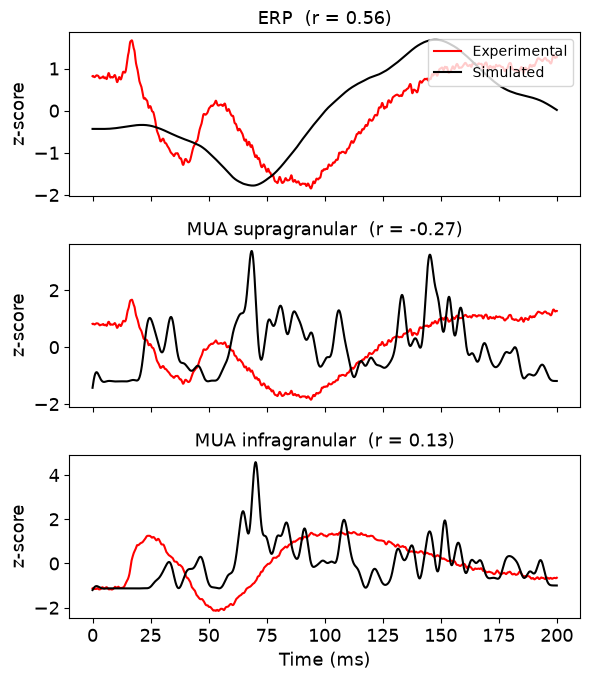

In [7]:
# z-score check plot
def _zscore(x):
    return (x - np.mean(x)) / np.std(x) if np.std(x) > 0 else x * 0

# simulated signals from the baseline network
sim_erp = dpl[0].copy().smooth(window_length).data['agg']
panels = [('ERP', sim_erp, exp_erp)]
for m in mua_targets:
    sim = _sim_mua(net, times, m, fr_smooth_ms)
    panels.append((m['name'], sim, m['trace']))

fig, axes = plt.subplots(len(panels), 1, figsize=(6, 2.3 * len(panels)), sharex=True)
for ax, (title, sim, exp) in zip(axes, panels):
    r = _safe_corr(sim, exp)
    ax.plot(times, _zscore(exp), color='r', label='Experimental')
    ax.plot(times, _zscore(sim), color='k', label='Simulated')
    ax.set_title(f'{title}  (r = {r:.2f})', fontsize=labelsize)
    ax.set_ylabel('z-score', fontsize=labelsize)
    ax.tick_params(labelsize=ticksize)
axes[0].legend(fontsize=10, loc='upper right')
axes[-1].set_xlabel('Time (ms)', fontsize=labelsize)
fig.tight_layout()

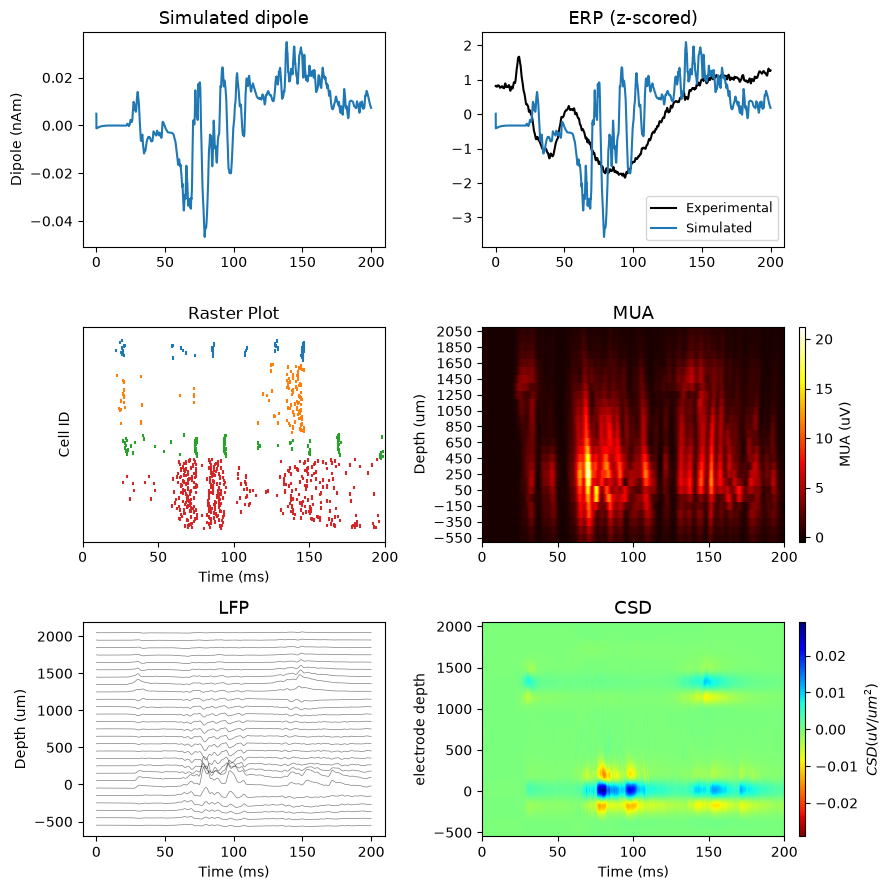

In [8]:
# Diagnostic: dipole, spikes, MUA, LFP and CSD of the baseline network
arr = net.rec_arrays['shank1']
rec_times, mua = _mua_all_contacts(net)
contact_depths = np.array(arr.positions)[:, 2]

fs = 1000 / (rec_times[1] - rec_times[0])
sos_lfp = signal.butter(4, 300, btype='lowpass', output='sos', fs=fs)
lfp = signal.sosfiltfilt(sos_lfp, np.array(arr.voltages), axis=-1).mean(axis=0)   # (n_contacts, n_times)
lfp_scale = 1    # adjust so LFP traces don't overlap (contacts are 100 um apart)

fig, ax = plt.subplots(3, 2, figsize=(9, 9))

# Row 0: simulated dipole (trials + average) | simulated vs experimental (z-scored)
for d in dpl:
    ax[0, 0].plot(d.times, d.data['agg'], color='tab:blue', alpha=0.2, linewidth=0.5)
avg_dpl = np.mean([d.data['agg'] for d in dpl], axis=0)
ax[0, 0].plot(times, avg_dpl, color='tab:blue')
ax[0, 0].set_title('Simulated dipole', fontsize=labelsize)
ax[0, 0].set_ylabel('Dipole (nAm)')
ax[0, 1].plot(times, _zscore(exp_erp), color='k', label='Experimental')
ax[0, 1].plot(times, _zscore(avg_dpl), color='tab:blue', label='Simulated')
ax[0, 1].set_title('ERP (z-scored)', fontsize=labelsize)
ax[0, 1].legend(fontsize=9)

# Row 1: spike raster | MUA across depth
net.cell_response.plot_spikes_raster(ax=ax[1, 0], show=False, show_legend=False)
im = ax[1, 1].pcolormesh(rec_times, contact_depths, mua, cmap='hot', shading='auto')
ax[1, 1].set_yticks(contact_depths[::2])
ax[1, 1].set_ylabel('Depth (um)')
ax[1, 1].set_title('MUA', fontsize=labelsize)
cax = ax[1, 1].inset_axes([1.05, 0, 0.02, 1], transform=ax[1, 1].transAxes)
plt.colorbar(im, cax=cax).set_label('MUA (uV)')

# Row 2: LFP traces at each depth | CSD
for c, l in enumerate(lfp):
    ax[2, 0].plot(rec_times, l * lfp_scale + contact_depths[c], color='k', alpha=0.5, linewidth=0.5)
ax[2, 0].set_title('LFP', fontsize=labelsize)
ax[2, 0].set_ylabel('Depth (um)')
arr.copy().plot_csd(ax=ax[2, 1], show=False, interpolation='spline', sink='r')
ax[2, 1].set_title('CSD', fontsize=labelsize)

for a in ax[-1]:
    a.set_xlabel('Time (ms)')
fig.tight_layout()

## Objective function

In [9]:
def _corr_mua_dpl(
    initial_net,
    initial_params,
    set_params,
    predicted_params,
    update_params,
    obj_values,
    tstop,
    obj_fun_kwargs,
):
    """Objective function: fit the dipole (ERP) and one or more MUA traces.

    obj_fun_kwargs["target"] must be a dict:
        {'dpl': array, 'mua': [{'trace': array, 'depth': float  (or 'cell_types': tuple)}, ...]}
    Loss per network = w_dpl * (1 - r_dipole) + (1 - w_dpl) * mean over MUA of (1 - r_mua)
    """
    # --- same batch setup as _corr_csd ---
    predicted_params = np.array(predicted_params).reshape(-1, len(initial_params))
    params_batch = {
        name: predicted_params[:, idx]
        for idx, name in enumerate(initial_params.keys())
    }

    new_net = initial_net.copy()

    def set_params_batch(a, b):
        set_params(b, a)

    batch_simulation = BatchSimulate(
        net=new_net,
        set_params=set_params_batch,
        save_outputs=False,
        save_dpl=True,
        dt=obj_fun_kwargs.get("dt", 0.025),
        n_trials=obj_fun_kwargs.get("n_trials", 1),
        tstop=tstop,
        overwrite=False,
        clear_cache=False,
    )

    res = batch_simulation.run(
        params_batch,
        n_jobs=obj_fun_kwargs.get("n_jobs", 1),
        combinations=False,
        backend="loky",
        verbose=obj_fun_kwargs.get("verbose", True),
    )

    # --- new part: score dipole + MUA ---
    target = obj_fun_kwargs["target"]
    w_dpl = obj_fun_kwargs.get("w_dpl", 0.5)
    fr_smooth_ms = obj_fun_kwargs.get("fr_smooth_ms", 5.0)
    win = obj_fun_kwargs.get("smooth_window_len", 20)

    loss_dpl, loss_mua = [], []
    for batch_res in res["simulated_data"]:
        for data in batch_res:
            dpl = data["dpl"][0].copy().smooth(win)
            loss_dpl.append(1 - _safe_corr(dpl.data["agg"], target["dpl"]))

            row = []
            for m in target["mua"]:
                sim_mua = _sim_mua(data["net"], dpl.times, m, fr_smooth_ms)
                row.append(1 - _safe_corr(sim_mua, m["trace"]))
            loss_mua.append(row)

    loss_dpl = np.array(loss_dpl)          # (n_networks,)
    loss_mua = np.array(loss_mua)          # (n_networks, n_mua)

    obj = w_dpl * loss_dpl + (1 - w_dpl) * loss_mua.mean(axis=1)
    obj_values.append(obj.tolist())

    best = np.argmin(obj)
    mua_str = " / ".join(f"{l:.2f}" for l in loss_mua[best])
    print(f"Mean loss {obj.mean():.2f} | Best: total {obj[best]:.2f}, "
          f"dipole {loss_dpl[best]:.2f}, MUA {mua_str}")
    return obj

## Optimization

In [10]:
net_base = jones_2009_model()
net_base.add_electrode_array('shank1', electrode_pos)

constraints, initial_params = add_opt_drives(net_base, n_prox=3, n_dist=3)

optim = Optimizer(net_base, tstop=tstop, constraints=constraints, solver='cma',
                  set_params=set_params_opt_drives, initial_params=initial_params,
                  max_iter=max_iter, obj_fun=_corr_mua_dpl)

target = {'dpl': exp_erp, 'mua': mua_targets}
optim.fit(target=target, n_trials=n_trials, smooth_window_len=window_length, dt=dt,
          popsize=popsize, n_jobs=n_jobs, verbose=False,
          w_dpl=w_dpl, fr_smooth_ms=fr_smooth_ms)

(2_w,4mirr1)-aCMA-ES (mu_w=1.5,w_1=80%) in dimension 66 (seed=1036970, Thu Nov  5 14:56:34 2026)


/Users/annacattani/Documents/Git_repos/CSD_optimization/.pixi/envs/default/lib/python3.12/site-packages/hnn_core/optimization/general_optimization.py:101: UserWarning: The cma solver does not use initial_params.Values passed will not be used
  warn(


Mean loss 1.15 | Best: total 0.84, dipole 0.97, MUA 1.04 / 0.40
Mean loss 1.09 | Best: total 0.81, dipole 0.92, MUA 0.88 / 0.51
termination on {'maxiter': 2}
final/bestever f-value = 8.082214e-01 8.082214e-01 after 8/8 evaluations
incumbent solution: [127.08723113   2.60752849   0.97226413  -3.80819852  -4.01715065
   0.2113427    0.2335458   -2.12487903 ...]
std deviations: [46.05753044  4.60807342  0.23043224  1.38256519  1.38305549  1.38203587
  1.3822785   1.38213941 ...]


In [11]:
# Uncomment to save (not worth it for test runs with small max_iter/popsize)

# Parameters of the best-fit network
# optim.net_.write_configuration('../data/opt_mua_dpl_config.json')

# Whole optimizer object
# with open('../data/opt_mua_dpl_results.pkl', 'wb') as file:
#     pickle.dump(optim, file)

## Results

In [12]:
# Simulate the best-fit network (10 trials, for averaging)
with JoblibBackend(n_jobs=n_jobs):
    dipoles_optimized = simulate_dipole(
        optim.net_, tstop=tstop, n_trials=10, dt=dt, verbose=False)

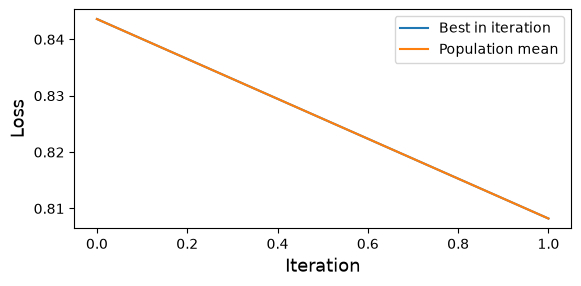

In [13]:
# optim.obj_ holds, for each iteration, the loss of every network in the population
best_per_iter = [np.min(o) for o in optim.obj_]
mean_per_iter = [np.mean(o) for o in optim.obj_]

plt.figure(figsize=(6, 3))
plt.plot(best_per_iter, label='Best in iteration')
plt.plot(mean_per_iter, label='Population mean')
plt.xlabel('Iteration', fontsize=labelsize)
plt.ylabel('Loss', fontsize=labelsize)
plt.legend(fontsize=10)
plt.tight_layout()

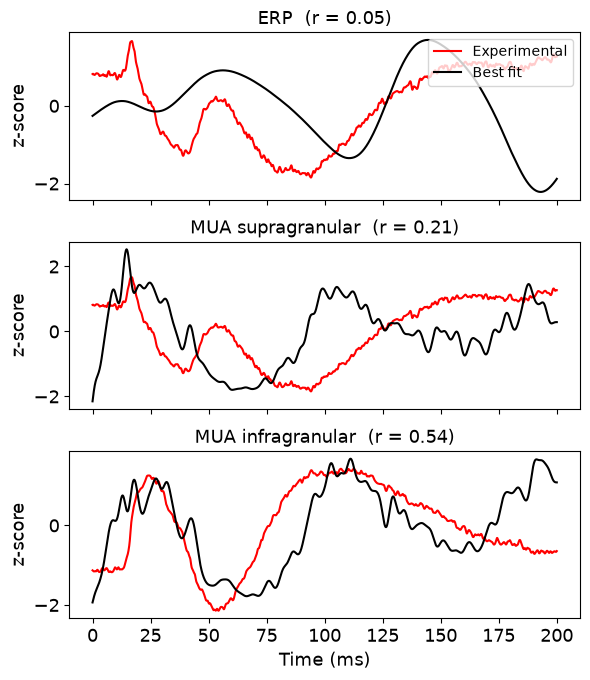

In [14]:
# Best fit vs experimental (z-scored), averaged over the simulated trials
n_sim_trials = len(dipoles_optimized)

sim_erp = np.mean([d.copy().smooth(window_length).data['agg'] for d in dipoles_optimized], axis=0)
panels = [('ERP', sim_erp, exp_erp)]
for m in mua_targets:
    sim = _sim_mua(optim.net_, times, m, fr_smooth_ms)
    panels.append((m['name'], sim, m['trace']))

fig, axes = plt.subplots(len(panels), 1, figsize=(6, 2.3 * len(panels)), sharex=True)
for ax, (title, sim, exp) in zip(axes, panels):
    r = _safe_corr(sim, exp)
    ax.plot(times, _zscore(exp), color='r', label='Experimental')
    ax.plot(times, _zscore(sim), color='k', label='Best fit')
    ax.set_title(f'{title}  (r = {r:.2f})', fontsize=labelsize)
    ax.set_ylabel('z-score', fontsize=labelsize)
    ax.tick_params(labelsize=ticksize)
axes[0].legend(fontsize=10, loc='upper right')
axes[-1].set_xlabel('Time (ms)', fontsize=labelsize)
fig.tight_layout()

(0.0, 255.0)

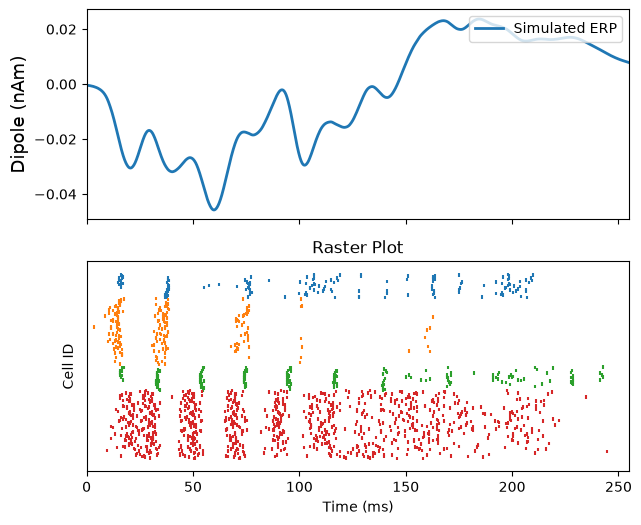

In [43]:
# Best-fit ERP (trial 0) and spike raster
fig, axes = plt.subplots(2, 1, figsize=(7,6), sharex=True)
axes[0].plot(times, dipoles_optimized[0].copy().smooth(20).data['agg'], linewidth=2, color=f'C0', label='Simulated ERP')
# axes[0].set_ylim(ymin, ymax)
axes[0].set_ylabel('Dipole (nAm)', fontsize=labelsize)
axes[0].legend(loc='upper right', fontsize=10)
optim.net_.cell_response.plot_spikes_raster(ax=axes[1], trial_idx=0, show=False, show_legend=False)
axes[0].set_xlim(None, 255)